In [2]:
# PHẦN A: CHUẨN BỊ MÔI TRƯỜNG
# Bước 1: Kiểm tra phiên bản Python và Java

import sys

print("Phiên bản Python:")
print(sys.version)

print("\nPhiên bản Java:")
!java -version

Phiên bản Python:
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

Phiên bản Java:
[0.013s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.013s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [3]:
# Bước 2: Cài đặt và chọn Java 17 cho Spark

!apt-get -qq update
!apt-get -qq install -y openjdk-17-jdk-headless

import os
from pathlib import Path

# Tìm thư mục Java 17 vừa cài
java17_path = next(Path("/usr/lib/jvm").glob("java-17-openjdk-*"))

# Chỉ định Java mà Spark và phiên làm việc sẽ sử dụng
os.environ["JAVA_HOME"] = str(java17_path)
os.environ["PATH"] = str(java17_path / "bin") + ":" + os.environ["PATH"]

# Kiểm tra kết quả
!java -version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't

In [5]:
# Bước 3: Cài PySpark với phiên bản cố định
%pip install "pyspark==4.0.1"

# Kiểm tra thư viện đã được nạp đúng phiên bản
import pyspark

print("Phiên bản PySpark:", pyspark.__version__)

assert pyspark.__version__ == "4.0.1", "Phiên bản PySpark chưa đúng!"
print("ĐẠT: Đã cài và nạp đúng PySpark 4.0.1")

Phiên bản PySpark: 4.0.1
ĐẠT: Đã cài và nạp đúng PySpark 4.0.1


In [6]:
# Bước 4: Khởi tạo Spark và kiểm tra hoạt động

import os
import sys
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Spark sử dụng cùng Python với notebook
os.environ["PYSPARK_PYTHON"] = sys.executable

# Khởi tạo phiên Spark
spark = (
    SparkSession.builder
    .appName("Airlines_TV1")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

print("Phiên bản Spark đang chạy:", spark.version)
assert spark.version == "4.0.1", "Spark đang chạy sai phiên bản!"

# Tạo bảng thử có 3 dòng
test_df = spark.createDataFrame(
    [(1, 10), (2, 20), (3, 30)],
    schema="id INT, value INT"
)

test_df.show()

# Kiểm tra số dòng và kết quả tính tổng
result = test_df.agg(
    F.count("*").alias("so_dong"),
    F.sum("value").alias("tong")
).first()

assert result["so_dong"] == 3, "Số dòng không đúng!"
assert result["tong"] == 60, "Kết quả tính tổng không đúng!"

print("ĐẠT: Spark xử lý được bảng thử — 3 dòng, tổng bằng 60.")

Phiên bản Spark đang chạy: 4.0.1
+---+-----+
| id|value|
+---+-----+
|  1|   10|
|  2|   20|
|  3|   30|
+---+-----+

ĐẠT: Spark xử lý được bảng thử — 3 dòng, tổng bằng 60.


In [6]:
# Bước 5: Kết nối Google Drive và kiểm tra thư mục dự án

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive", force_remount=True)

# Thư mục bạn đã tạo trên Google Drive
PROJECT_DIR = Path("/content/drive/MyDrive/BigData_Topic20")

assert PROJECT_DIR.is_dir(), (
    "Không tìm thấy BigData_Topic20. "
    "Kiểm tra tài khoản Google và tên thư mục."
)

# Kiểm tra đủ ba thư mục con
for folder_name in ["01_data_frozen", "02_models", "03_results"]:
    folder_path = PROJECT_DIR / folder_name
    assert folder_path.is_dir(), f"Thiếu thư mục: {folder_name}"
    print("Đã tìm thấy:", folder_name)

print("ĐẠT: Đã kết nối Drive và tìm thấy đủ thư mục dự án.")

Mounted at /content/drive
Đã tìm thấy: 01_data_frozen
Đã tìm thấy: 02_models
Đã tìm thấy: 03_results
ĐẠT: Đã kết nối Drive và tìm thấy đủ thư mục dự án.


In [7]:
# PHẦN B: THU THẬP VÀ KIỂM TRA DỮ LIỆU
# Bước 6: Tải Airlines từ OpenML, ID 1169

from sklearn.datasets import fetch_openml

airlines = fetch_openml(
    data_id=1169,
    as_frame=True,
    data_home="/content/openml_cache"
)

# Giữ một bảng dữ liệu gốc để đối chiếu về sau
df_raw = airlines.frame.copy()

print("Tên dataset:", airlines.details["name"])
print("ID dataset:", airlines.details["id"])
print("Số dòng:", df_raw.shape[0])
print("Số cột:", df_raw.shape[1])
print("Các cột:", df_raw.columns.tolist())

# Kiểm tra đúng nguồn và cấu trúc mong đợi
expected_columns = {
    "Airline", "Flight", "AirportFrom", "AirportTo",
    "DayOfWeek", "Time", "Length", "Delay"
}

assert str(airlines.details["id"]) == "1169", "Sai ID dataset!"
assert df_raw.shape == (539383, 8), "Số dòng hoặc số cột khác kỳ vọng!"
assert set(df_raw.columns) == expected_columns, "Tên cột khác kỳ vọng!"

display(df_raw.head())

print("ĐẠT: Đã tải đúng nguồn và đúng cấu trúc ban đầu.")

Tên dataset: airlines
ID dataset: 1169
Số dòng: 539383
Số cột: 8
Các cột: ['Airline', 'Flight', 'AirportFrom', 'AirportTo', 'DayOfWeek', 'Time', 'Length', 'Delay']


,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
0,CO,269,SFO,IAH,3,15,205,1
1,US,1558,PHX,CLT,3,15,222,1
2,AA,2400,LAX,DFW,3,20,165,1
3,AA,2466,SFO,DFW,3,20,195,1
4,AS,108,ANC,SEA,3,30,202,0


ĐẠT: Đã tải đúng nguồn và đúng cấu trúc ban đầu.


In [8]:
# Bước 7: Lưu dữ liệu gốc lên Drive và kiểm tra lại

import pandas as pd

# Thư mục dành cho phiên bản dữ liệu đầu tiên
DATA_DIR = PROJECT_DIR / "01_data_frozen" / "tv1_v1"
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

RAW_FILE = RAW_DIR / "airlines_1169_raw.csv"

# Chỉ tạo file nếu chưa có, tránh ghi đè bản nguồn đã lưu
if not RAW_FILE.exists():
    df_raw.to_csv(RAW_FILE, index=False, encoding="utf-8")
    print("Đã lưu file dữ liệu gốc.")
else:
    print("File đã tồn tại. Giữ nguyên và kiểm tra nội dung.")

# Đọc lại dạng chuỗi để đối chiếu các giá trị trong CSV
df_saved = pd.read_csv(
    RAW_FILE,
    dtype="string",
    keep_default_na=False
)

expected = df_raw.reset_index(drop=True).astype("string").fillna("")

# So sánh toàn bộ bảng, gồm tên cột, thứ tự dòng và giá trị
pd.testing.assert_frame_equal(df_saved, expected)

print("Đường dẫn:", RAW_FILE)
print("Số dòng, số cột:", df_saved.shape)
print("ĐẠT: Bản CSV trên Drive khớp với bảng dữ liệu vừa tải.")

# Giải phóng hai bảng phụ sau khi kiểm tra
del df_saved, expected

Đã lưu file dữ liệu gốc.
Đường dẫn: /content/drive/MyDrive/BigData_Topic20/01_data_frozen/tv1_v1/raw/airlines_1169_raw.csv
Số dòng, số cột: (539383, 8)
ĐẠT: Bản CSV trên Drive khớp với bảng dữ liệu vừa tải.


In [9]:
# PHẦN C: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU
# Bước 8: Khảo sát kiểu dữ liệu, giá trị thiếu và độ đa dạng

quality_summary = pd.DataFrame({
    "kieu_du_lieu": df_raw.dtypes.astype(str),
    "so_gia_tri_thieu": df_raw.isna().sum(),
    "ty_le_thieu_phan_tram": (
        df_raw.isna().mean() * 100
    ).round(4),
    "so_gia_tri_khac_nhau": df_raw.nunique()
})

quality_summary.index.name = "ten_cot"
display(quality_summary)

# Lưu bảng thống kê để dùng trong báo cáo
REPORT_DIR = DATA_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

quality_summary.to_csv(
    REPORT_DIR / "01_data_quality_summary.csv",
    encoding="utf-8-sig"
)

print("HOÀN TẤT: Đã khảo sát và lưu bảng chất lượng ban đầu.")

,kieu_du_lieu,so_gia_tri_thieu,ty_le_thieu_phan_tram,so_gia_tri_khac_nhau
ten_cot,,,,
Airline,category,0,0.0,18
Flight,int64,0,0.0,6585
AirportFrom,category,0,0.0,293
AirportTo,category,0,0.0,293
DayOfWeek,category,0,0.0,7
Time,int64,0,0.0,1131
Length,int64,0,0.0,426
Delay,category,0,0.0,2


HOÀN TẤT: Đã khảo sát và lưu bảng chất lượng ban đầu.


In [10]:
# Bước 9: Kiểm tra nhãn và thống kê tỷ lệ hai lớp

# Chuyển nhãn sang số trong một biến riêng, giữ nguyên df_raw
delay_numeric = pd.to_numeric(df_raw["Delay"], errors="raise")

# Kiểm tra trước khi chuyển thành số nguyên
assert delay_numeric.notna().all(), "Nhãn có giá trị thiếu!"
assert set(delay_numeric.unique()) == {0, 1}, (
    "Nhãn không đúng hai giá trị 0 và 1!"
)

delay_numeric = delay_numeric.astype("int64")

# Đếm số dòng của từng lớp
label_summary = (
    delay_numeric.value_counts()
    .sort_index()
    .rename_axis("Delay")
    .reset_index(name="so_chuyen")
)

label_summary["y_nghia"] = label_summary["Delay"].map({
    0: "Không trễ",
    1: "Trễ"
})

label_summary["ty_le_phan_tram"] = (
    label_summary["so_chuyen"] / len(df_raw) * 100
).round(4)

assert label_summary["so_chuyen"].sum() == len(df_raw)

display(label_summary)

label_summary.to_csv(
    REPORT_DIR / "02_label_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

print("ĐẠT: Nhãn chỉ gồm 0 và 1, không thiếu và thống kê đủ số dòng.")

,Delay,so_chuyen,y_nghia,ty_le_phan_tram
0,0,299119,Không trễ,55.4558
1,1,240264,Trễ,44.5442


ĐẠT: Nhãn chỉ gồm 0 và 1, không thiếu và thống kê đủ số dòng.


In [11]:
# Bước 10: Thống kê dòng trùng, chưa xóa dữ liệu

feature_columns = [
    col for col in df_raw.columns if col != "Delay"
]

# Đếm những lần xuất hiện lặp lại sau lần đầu tiên
duplicate_all = int(
    df_raw.duplicated(keep="first").sum()
)

duplicate_features = int(
    df_raw.duplicated(
        subset=feature_columns,
        keep="first"
    ).sum()
)

duplicate_summary = pd.DataFrame({
    "truong_hop": [
        "Trùng cả 8 cột, gồm Delay",
        "Trùng 7 đặc trưng, không xét Delay"
    ],
    "so_dong_lap_sau_lan_dau": [
        duplicate_all,
        duplicate_features
    ]
})

display(duplicate_summary)

# Hiển thị một số dòng thuộc các nhóm trùng cả 8 cột
print("Ví dụ các dòng thuộc nhóm trùng cả 8 cột:")
display(df_raw.loc[df_raw.duplicated(keep=False)].head(10))

duplicate_summary.to_csv(
    REPORT_DIR / "03_duplicate_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("HOÀN TẤT: Đã thống kê dòng trùng, giữ nguyên dữ liệu gốc.")

,truong_hop,so_dong_lap_sau_lan_dau
0,"Trùng cả 8 cột, gồm Delay",216618
1,"Trùng 7 đặc trưng, không xét Delay",311991


Ví dụ các dòng thuộc nhóm trùng cả 8 cột:


ten_cot,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
0,CO,269,SFO,IAH,3,15,205,1
1,US,1558,PHX,CLT,3,15,222,1
2,AA,2400,LAX,DFW,3,20,165,1
3,AA,2466,SFO,DFW,3,20,195,1
4,AS,108,ANC,SEA,3,30,202,0
5,CO,1094,LAX,IAH,3,30,181,1
9,AA,2538,LAS,ORD,3,40,200,1
10,CO,223,ANC,SEA,3,49,201,1
12,DL,2055,SLC,ATL,3,50,210,0
13,AA,2408,LAX,DFW,3,55,170,0


HOÀN TẤT: Đã thống kê dòng trùng, giữ nguyên dữ liệu gốc.


In [12]:
# Bước 11: Kiểm tra miền giá trị, chưa sửa dữ liệu

import numpy as np

columns_to_check = ["DayOfWeek", "Time", "Length", "Flight"]

# Tạo bảng phụ dạng số để kiểm tra
# Giá trị không chuyển được thành số sẽ thành NaN và bị đánh dấu
numeric_check = df_raw[columns_to_check].apply(
    pd.to_numeric,
    errors="coerce"
)

# True nghĩa là giá trị không đạt quy tắc
invalid_masks = {
    "DayOfWeek": ~numeric_check["DayOfWeek"].isin(range(1, 8)),

    "Time": ~(
        np.isfinite(numeric_check["Time"])
        & numeric_check["Time"].between(0, 1439)
    ),

    "Length": ~(
        np.isfinite(numeric_check["Length"])
        & (numeric_check["Length"] > 0)
    ),

    "Flight": ~(
        np.isfinite(numeric_check["Flight"])
        & (numeric_check["Flight"] > 0)
        & (numeric_check["Flight"] % 1 == 0)
    )
}

range_summary = pd.DataFrame({
    "gia_tri_nho_nhat": numeric_check.min(),
    "gia_tri_lon_nhat": numeric_check.max(),
    "so_dong_khong_hop_le": pd.Series({
        col: int(mask.sum())
        for col, mask in invalid_masks.items()
    })
})

range_summary.index.name = "ten_cot"
display(range_summary)

# Xem các dòng có Length bất thường, tối đa 20 dòng
print("Các dòng có Length không hợp lệ:")
display(df_raw.loc[invalid_masks["Length"]].head(20))

range_summary.to_csv(
    REPORT_DIR / "04_value_range_summary.csv",
    encoding="utf-8-sig"
)

print("HOÀN TẤT: Đã kiểm tra miền giá trị, chưa thay đổi dữ liệu gốc.")

,gia_tri_nho_nhat,gia_tri_lon_nhat,so_dong_khong_hop_le
ten_cot,,,
DayOfWeek,1,7,0
Time,10,1439,0
Length,0,655,4
Flight,1,7814,0


Các dòng có Length không hợp lệ:


ten_cot,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
179149,F9,106,DEN,MSP,6,635,0,0
182840,F9,107,MSP,DEN,6,851,0,0
188953,F9,103,MSP,DEN,7,375,0,0
445578,B6,493,BOS,SEA,7,1060,0,1


HOÀN TẤT: Đã kiểm tra miền giá trị, chưa thay đổi dữ liệu gốc.


In [13]:
# Bước 12: Gắn row_id và đọc dữ liệu bằng Spark

from pathlib import Path
from pyspark.sql import functions as F

# Tạo bảng riêng, giữ nguyên df_raw
df_stage = df_raw.reset_index(drop=True).copy()
df_stage.insert(0, "row_id", range(len(df_stage)))

# Ghi bản trung gian vào đĩa cục bộ Colab
LOCAL_DIR = Path("/content/airlines_tv1")
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

STAGING_FILE = LOCAL_DIR / "airlines_with_row_id.csv"
df_stage.to_csv(STAGING_FILE, index=False, encoding="utf-8")

# Khai báo kiểu rõ ràng, không để Spark tự đoán
raw_schema = """
    row_id LONG,
    Airline STRING,
    Flight LONG,
    AirportFrom STRING,
    AirportTo STRING,
    DayOfWeek STRING,
    Time DOUBLE,
    Length DOUBLE,
    Delay INT
"""

spark_raw = (
    spark.read
    .option("header", True)
    .option("enforceSchema", False)
    .option("mode", "FAILFAST")
    .schema(raw_schema)
    .csv(str(STAGING_FILE))
)

# Kiểm tra số dòng và tính duy nhất của row_id
id_check = spark_raw.agg(
    F.count("*").alias("so_dong"),
    F.count("row_id").alias("so_id_khong_null"),
    F.countDistinct("row_id").alias("so_id_khac_nhau")
).first()

assert id_check["so_dong"] == 539383
assert id_check["so_id_khong_null"] == 539383
assert id_check["so_id_khac_nhau"] == 539383

spark_raw.printSchema()
spark_raw.orderBy("row_id").show(5, truncate=False)

print("ĐẠT: Spark đọc đủ 539383 dòng; row_id không thiếu và không trùng.")

del df_stage

root
 |-- row_id: long (nullable = true)
 |-- Airline: string (nullable = true)
 |-- Flight: long (nullable = true)
 |-- AirportFrom: string (nullable = true)
 |-- AirportTo: string (nullable = true)
 |-- DayOfWeek: string (nullable = true)
 |-- Time: double (nullable = true)
 |-- Length: double (nullable = true)
 |-- Delay: integer (nullable = true)

+------+-------+------+-----------+---------+---------+----+------+-----+
|row_id|Airline|Flight|AirportFrom|AirportTo|DayOfWeek|Time|Length|Delay|
+------+-------+------+-----------+---------+---------+----+------+-----+
|0     |CO     |269   |SFO        |IAH      |3        |15.0|205.0 |1    |
|1     |US     |1558  |PHX        |CLT      |3        |15.0|222.0 |1    |
|2     |AA     |2400  |LAX        |DFW      |3        |20.0|165.0 |1    |
|3     |AA     |2466  |SFO        |DFW      |3        |20.0|195.0 |1    |
|4     |AS     |108   |ANC        |SEA      |3        |30.0|202.0 |0    |
+------+-------+------+-----------+---------+---------

In [14]:
# Bước 13: Chuẩn hóa kiểu và đánh dấu Length bất thường

# Kiểm tra Spark không phát sinh null khi đọc dữ liệu nguồn
raw_nulls = spark_raw.agg(*[
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in spark_raw.columns
]).first().asDict()

assert all(n == 0 for n in raw_nulls.values()), (
    f"Spark đọc ra giá trị null cần kiểm tra: {raw_nulls}"
)

# Tạo bảng mới, giữ nguyên spark_raw
clean_df = (
    spark_raw
    .withColumn("Flight", F.col("Flight").cast("string"))
    .withColumn(
        "Length_invalid",
        F.when(F.col("Length") <= 0, 1).otherwise(0)
    )
    .withColumn(
        "Length",
        F.when(
            F.col("Length_invalid") == 1,
            F.lit(None).cast("double")
        ).otherwise(F.col("Length"))
    )
)

# Kiểm tra kết quả làm sạch
clean_check = clean_df.agg(
    F.count("*").alias("so_dong"),
    F.countDistinct("row_id").alias("so_id_khac_nhau"),
    F.sum("Length_invalid").alias("so_dong_danh_dau"),
    F.sum(F.col("Length").isNull().cast("int")).alias("so_length_null")
).first().asDict()

assert clean_check["so_dong"] == 539383
assert clean_check["so_id_khac_nhau"] == 539383
assert clean_check["so_dong_danh_dau"] == 4
assert clean_check["so_length_null"] == 4
assert dict(clean_df.dtypes)["Flight"] == "string"

print("Kết quả kiểm tra:", clean_check)

clean_df.filter(
    F.col("Length_invalid") == 1
).orderBy("row_id").show(truncate=False)

print("ĐẠT: Giữ đủ số dòng; đã đánh dấu và chuyển 4 Length bất thường thành null.")

Kết quả kiểm tra: {'so_dong': 539383, 'so_id_khac_nhau': 539383, 'so_dong_danh_dau': 4, 'so_length_null': 4}
+------+-------+------+-----------+---------+---------+------+------+-----+--------------+
|row_id|Airline|Flight|AirportFrom|AirportTo|DayOfWeek|Time  |Length|Delay|Length_invalid|
+------+-------+------+-----------+---------+---------+------+------+-----+--------------+
|179149|F9     |106   |DEN        |MSP      |6        |635.0 |NULL  |0    |1             |
|182840|F9     |107   |MSP        |DEN      |6        |851.0 |NULL  |0    |1             |
|188953|F9     |103   |MSP        |DEN      |7        |375.0 |NULL  |0    |1             |
|445578|B6     |493   |BOS        |SEA      |7        |1060.0|NULL  |1    |1             |
+------+-------+------+-----------+---------+---------+------+------+-----+--------------+

ĐẠT: Giữ đủ số dòng; đã đánh dấu và chuyển 4 Length bất thường thành null.


In [15]:
# Bước 14: Lưu Parquet trên Colab và kiểm tra toàn bộ nội dung

CLEAN_LOCAL_DIR = LOCAL_DIR / "clean"

# Không ghi đè nếu thư mục đã tồn tại
if not CLEAN_LOCAL_DIR.exists():
    clean_df.write.mode("errorifexists").parquet(
        str(CLEAN_LOCAL_DIR)
    )
    print("Đã ghi bản Parquet.")
else:
    print("Bản Parquet đã tồn tại. Đọc lại để kiểm tra.")

# Đọc lại và giữ đúng thứ tự cột để so sánh
clean_fixed = (
    spark.read.parquet(str(CLEAN_LOCAL_DIR))
    .select(*clean_df.columns)
)

# Kiểm tra tên cột và kiểu dữ liệu
assert clean_fixed.dtypes == clean_df.dtypes, (
    "Tên cột hoặc kiểu dữ liệu thay đổi sau khi lưu!"
)

# Kiểm tra số dòng
saved_count = clean_fixed.count()
assert saved_count == 539383, "Số dòng sau khi lưu không đúng!"

# So sánh toàn bộ bản ghi theo cả hai chiều
# exceptAll giữ cả số lần lặp của các bản ghi
assert clean_df.exceptAll(clean_fixed).limit(1).count() == 0, (
    "Bản lưu bị thiếu hoặc khác dữ liệu trước khi lưu!"
)

assert clean_fixed.exceptAll(clean_df).limit(1).count() == 0, (
    "Bản lưu có dữ liệu thừa hoặc khác dữ liệu trước khi lưu!"
)

print("Đường dẫn:", CLEAN_LOCAL_DIR)
print("Số dòng đọc lại:", saved_count)
print("ĐẠT: Parquet giữ nguyên kiểu dữ liệu và toàn bộ bản ghi.")

Đã ghi bản Parquet.
Đường dẫn: /content/airlines_tv1/clean
Số dòng đọc lại: 539383
ĐẠT: Parquet giữ nguyên kiểu dữ liệu và toàn bộ bản ghi.


In [16]:
# Bước 15: Sao lưu bản clean lên Drive và kiểm tra nội dung file

import shutil
import hashlib
import json

CLEAN_DRIVE_DIR = DATA_DIR / "clean"

# Spark đã ghi xong thư mục nguồn
assert (CLEAN_LOCAL_DIR / "_SUCCESS").is_file(), (
    "Chưa tìm thấy dấu hiệu Spark ghi thành công!"
)

# Giữ nguyên bản đã có trên Drive, không tự ghi đè
if not CLEAN_DRIVE_DIR.exists():
    shutil.copytree(CLEAN_LOCAL_DIR, CLEAN_DRIVE_DIR)
    print("Đã sao chép thư mục clean lên Drive.")
else:
    print("Thư mục clean đã tồn tại. Kiểm tra bản hiện có.")

# Tính mã kiểm tra cho từng file trong thư mục
def folder_checksums(folder):
    return {
        path.relative_to(folder).as_posix():
            hashlib.sha256(path.read_bytes()).hexdigest()
        for path in sorted(folder.rglob("*"))
        if path.is_file()
    }

local_checksums = folder_checksums(CLEAN_LOCAL_DIR)
drive_checksums = folder_checksums(CLEAN_DRIVE_DIR)

assert local_checksums, "Thư mục nguồn không có file!"
assert local_checksums == drive_checksums, (
    "Bản Drive thiếu, thừa hoặc khác nội dung file. Dừng để kiểm tra."
)

# Lưu mã kiểm tra để nhóm có thể đối chiếu về sau
(REPORT_DIR / "05_clean_checksums.json").write_text(
    json.dumps(local_checksums, indent=2),
    encoding="utf-8"
)

print("Nơi lưu:", CLEAN_DRIVE_DIR)
print("Số file đã đối chiếu:", len(local_checksums))
print("ĐẠT: Bản clean trên Drive khớp từng file với bản Colab.")

Đã sao chép thư mục clean lên Drive.
Nơi lưu: /content/drive/MyDrive/BigData_Topic20/01_data_frozen/tv1_v1/clean
Số file đã đối chiếu: 6
ĐẠT: Bản clean trên Drive khớp từng file với bản Colab.


In [17]:
# Bước 16: Chia tập cố định theo row_id, tỷ lệ xấp xỉ 70/15/15

SEED = 42

# Tạo mã hash từ seed và row_id
split_hash = F.sha2(
    F.concat(
        F.lit(f"split:{SEED}:"),
        F.col("row_id").cast("string")
    ),
    256
)

# Chuyển 8 ký tự đầu của hash thành một số từ 0 đến 9999
split_bucket = F.pmod(
    F.conv(F.substring(split_hash, 1, 8), 16, 10).cast("long"),
    F.lit(10000)
)

# Mỗi dòng được gán đúng một tập
assigned_df = (
    clean_fixed
    .withColumn("_split_bucket", split_bucket)
    .withColumn(
        "_split",
        F.when(F.col("_split_bucket") < 7000, "train")
         .when(F.col("_split_bucket") < 8500, "val")
         .otherwise("test")
    )
    .cache()
)

# Tách ba tập; bỏ các cột phụ dùng để chia
train_base = assigned_df.filter(
    F.col("_split") == "train"
).drop("_split_bucket", "_split")

val_base = assigned_df.filter(
    F.col("_split") == "val"
).drop("_split_bucket", "_split")

test_base = assigned_df.filter(
    F.col("_split") == "test"
).drop("_split_bucket", "_split")

# Thống kê số dòng
split_summary = (
    assigned_df.groupBy("_split")
    .agg(F.count("*").alias("so_dong"))
    .withColumn(
        "ty_le_phan_tram",
        F.round(F.col("so_dong") / 539383 * 100, 4)
    )
    .orderBy("_split")
)

split_summary.show(truncate=False)

split_counts = {
    row["_split"]: row["so_dong"]
    for row in split_summary.collect()
}

assert set(split_counts) == {"train", "val", "test"}
assert sum(split_counts.values()) == 539383
assert all(n > 0 for n in split_counts.values())

print("ĐẠT: Đã tạo ba tập, tổng số dòng vẫn bằng 539383.")
print("Chưa điền Length và chưa hoàn tất kiểm định chia tập.")

+------+-------+---------------+
|_split|so_dong|ty_le_phan_tram|
+------+-------+---------------+
|test  |81028  |15.0223        |
|train |376749 |69.8481        |
|val   |81606  |15.1295        |
+------+-------+---------------+

ĐẠT: Đã tạo ba tập, tổng số dòng vẫn bằng 539383.
Chưa điền Length và chưa hoàn tất kiểm định chia tập.


In [18]:
# Bước 17: Kiểm tra tính toàn vẹn của ba tập theo row_id

from itertools import combinations

parts_base = {
    "train": train_base,
    "val": val_base,
    "test": test_base
}

integrity_results = []

# 1. Trong từng tập: row_id không thiếu và không lặp
for name, part in parts_base.items():
    stats = part.agg(
        F.count("*").alias("n"),
        F.count("row_id").alias("id_not_null"),
        F.countDistinct("row_id").alias("id_unique")
    ).first()

    assert stats["n"] == split_counts[name], f"{name}: số dòng thay đổi!"
    assert stats["n"] == stats["id_not_null"] == stats["id_unique"], (
        f"{name}: có row_id thiếu hoặc trùng!"
    )

    integrity_results.append({
        "kiem_tra": f"{name}: ID thiếu hoặc trùng",
        "so_vi_pham": 0
    })

# 2. Giữa từng cặp tập: không được có row_id chung
for name_a, name_b in combinations(parts_base, 2):
    overlap = (
        parts_base[name_a].select("row_id")
        .join(
            parts_base[name_b].select("row_id"),
            on="row_id",
            how="inner"
        )
        .count()
    )

    assert overlap == 0, f"{name_a} và {name_b} có {overlap} ID chung!"

    integrity_results.append({
        "kiem_tra": f"Giao nhau: {name_a} / {name_b}",
        "so_vi_pham": overlap
    })

# 3. Ghép ID của ba tập để đối chiếu với nguồn
all_split_ids = (
    train_base.select("row_id")
    .unionByName(val_base.select("row_id"))
    .unionByName(test_base.select("row_id"))
)

source_ids = clean_fixed.select("row_id")

missing_ids = source_ids.join(
    all_split_ids, "row_id", "left_anti"
).count()

extra_ids = all_split_ids.join(
    source_ids, "row_id", "left_anti"
).count()

assert missing_ids == 0, f"Bị mất {missing_ids} ID từ nguồn!"
assert extra_ids == 0, f"Xuất hiện {extra_ids} ID không có trong nguồn!"

integrity_results.extend([
    {"kiem_tra": "ID nguồn bị thiếu sau chia", "so_vi_pham": missing_ids},
    {"kiem_tra": "ID thừa so với nguồn", "so_vi_pham": extra_ids}
])

integrity_report = pd.DataFrame(integrity_results)
display(integrity_report)

integrity_report.to_csv(
    REPORT_DIR / "06_split_integrity.csv",
    index=False,
    encoding="utf-8-sig"
)

print("ĐẠT: Các tập tách biệt theo row_id, không mất hoặc thừa bản ghi.")

,kiem_tra,so_vi_pham
0,train: ID thiếu hoặc trùng,0
1,val: ID thiếu hoặc trùng,0
2,test: ID thiếu hoặc trùng,0
3,Giao nhau: train / val,0
4,Giao nhau: train / test,0
5,Giao nhau: val / test,0
6,ID nguồn bị thiếu sau chia,0
7,ID thừa so với nguồn,0


ĐẠT: Các tập tách biệt theo row_id, không mất hoặc thừa bản ghi.


In [19]:
# Bước 18: Kiểm tra phân phối nhãn sau khi chia tập

overall_delay_rate = float(
    clean_fixed.agg(F.avg("Delay")).first()[0]
)

split_label_rows = []

for name, part in parts_base.items():
    counts = part.agg(
        F.count("*").alias("n"),
        F.sum(F.when(F.col("Delay") == 0, 1).otherwise(0)).alias("n0"),
        F.sum(F.when(F.col("Delay") == 1, 1).otherwise(0)).alias("n1")
    ).first()

    # Không được có nhãn thiếu hoặc ngoài 0/1
    assert counts["n0"] + counts["n1"] == counts["n"], (
        f"{name}: có nhãn thiếu hoặc không hợp lệ!"
    )
    assert counts["n0"] > 0 and counts["n1"] > 0, (
        f"{name}: không có đủ hai lớp!"
    )

    delay_rate = counts["n1"] / counts["n"]

    split_label_rows.append({
        "tap": name,
        "so_dong": counts["n"],
        "khong_tre": counts["n0"],
        "tre": counts["n1"],
        "ty_le_tre_phan_tram": delay_rate * 100,
        "lech_diem_phan_tram": abs(
            delay_rate - overall_delay_rate
        ) * 100
    })

split_label_report = pd.DataFrame(split_label_rows)

print(f"Tỷ lệ trễ toàn bộ nguồn: {overall_delay_rate * 100:.4f}%")
display(split_label_report.round(4))

# Kiểm tra bằng giá trị chưa làm tròn
assert (
    split_label_report["lech_diem_phan_tram"] <= 0.5
).all(), "Có tập lệch quá 0,5 điểm phần trăm; cần kiểm tra!"

split_label_report.to_csv(
    REPORT_DIR / "07_split_label_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

print("ĐẠT: Các tập có đủ hai lớp và tỷ lệ nhãn nằm trong ngưỡng kiểm tra.")

Tỷ lệ trễ toàn bộ nguồn: 44.5442%


,tap,so_dong,khong_tre,tre,ty_le_tre_phan_tram,lech_diem_phan_tram
0,train,376749,208791,167958,44.5809,0.0366
1,val,81606,45165,36441,44.6548,0.1106
2,test,81028,45163,35865,44.2625,0.2818


ĐẠT: Các tập có đủ hai lớp và tỷ lệ nhãn nằm trong ngưỡng kiểm tra.


In [20]:
# Bước 19: Học trung vị từ Train và áp dụng cho cả ba tập

import math
import json

# approxQuantile bỏ qua null.
# Sai số bằng 0.0: tính phân vị chính xác, không dùng xấp xỉ.
median_values = train_base.approxQuantile(
    "Length", [0.5], 0.0
)

assert len(median_values) == 1, "Không tính được trung vị từ Train!"

length_median = float(median_values[0])

assert math.isfinite(length_median) and length_median > 0
print("Trung vị Length học từ Train:", length_median)

# Tạo các bảng mới, giữ nguyên các bảng *_base
parts_imputed = {}
imputation_rows = []

for name, part in parts_base.items():
    missing_before = part.filter(
        F.col("Length").isNull()
    ).count()

    filled = part.fillna({"Length": length_median})

    # Kiểm tra số dòng và Length sau xử lý
    check = filled.agg(
        F.count("*").alias("n"),
        F.sum(
            F.when(
                F.col("Length").isNull()
                | F.isnan("Length")
                | (F.col("Length") <= 0)
                | (F.abs(F.col("Length")) == float("inf")),
                1
            ).otherwise(0)
        ).alias("invalid_length")
    ).first()

    assert check["n"] == split_counts[name], f"{name}: số dòng thay đổi!"
    assert check["invalid_length"] == 0, f"{name}: Length vẫn không hợp lệ!"

    parts_imputed[name] = filled

    imputation_rows.append({
        "tap": name,
        "so_dong": check["n"],
        "so_length_da_dien": missing_before,
        "length_khong_hop_le_sau_xu_ly": check["invalid_length"]
    })

train_imputed = parts_imputed["train"]
val_imputed = parts_imputed["val"]
test_imputed = parts_imputed["test"]

imputation_report = pd.DataFrame(imputation_rows)
display(imputation_report)

# Lưu quy tắc để TV2 và phần demo dùng lại
preprocessing_config = {
    "length_invalid_rule": "Length <= 0 becomes null",
    "length_imputation_method": "train_median",
    "length_median": length_median,
    "fit_on": "train_only",
    "retain_Length_invalid": True
}

(DATA_DIR / "preprocessing.json").write_text(
    json.dumps(preprocessing_config, indent=2),
    encoding="utf-8"
)

imputation_report.to_csv(
    REPORT_DIR / "08_length_imputation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("ĐẠT: Đã điền Length bằng trung vị Train và giữ nguyên số dòng.")

Trung vị Length học từ Train: 115.0


,tap,so_dong,so_length_da_dien,length_khong_hop_le_sau_xu_ly
0,train,376749,3,0
1,val,81606,1,0
2,test,81028,0,0


ĐẠT: Đã điền Length bằng trung vị Train và giữ nguyên số dòng.


In [21]:
# Bước 20: Gán 5 fold cố định, chỉ cho Train

# Dùng tiền tố "fold" khác "split" để tạo cách phân nhóm riêng
fold_hash = F.sha2(
    F.concat(
        F.lit(f"fold:{SEED}:"),
        F.col("row_id").cast("string")
    ),
    256
)

fold_number = F.pmod(
    F.conv(F.substring(fold_hash, 1, 8), 16, 10).cast("long"),
    F.lit(5)
).cast("int")

# Train có thêm fold; Validation và Test giữ nguyên
train_final = train_imputed.withColumn("fold", fold_number)
val_final = val_imputed
test_final = test_imputed

# Thống kê từng fold
fold_summary = (
    train_final.groupBy("fold")
    .agg(
        F.count("*").alias("so_dong"),
        F.sum(F.when(F.col("Delay") == 0, 1).otherwise(0)).alias("khong_tre"),
        F.sum(F.when(F.col("Delay") == 1, 1).otherwise(0)).alias("tre"),
        (F.avg("Delay") * 100).alias("ty_le_tre_phan_tram")
    )
    .orderBy("fold")
)

# Chỉ chuyển bảng tổng hợp 5 dòng về Pandas
fold_report = fold_summary.toPandas()

assert set(fold_report["fold"]) == {0, 1, 2, 3, 4}
assert int(fold_report["so_dong"].sum()) == split_counts["train"]
assert (fold_report["khong_tre"] > 0).all()
assert (fold_report["tre"] > 0).all()
assert "fold" not in val_final.columns
assert "fold" not in test_final.columns

display(fold_report.round(4))

fold_report.to_csv(
    REPORT_DIR / "09_train_folds.csv",
    index=False,
    encoding="utf-8-sig"
)

print("ĐẠT: Train có đủ 5 fold, giữ nguyên tổng số dòng.")
print("Validation và Test không có cột fold.")

,fold,so_dong,khong_tre,tre,ty_le_tre_phan_tram
0,0,75305,41852,33453,44.4233
1,1,75042,41599,33443,44.5657
2,2,75213,41679,33534,44.5854
3,3,75408,41595,33813,44.8401
4,4,75781,42066,33715,44.4900


ĐẠT: Train có đủ 5 fold, giữ nguyên tổng số dòng.
Validation và Test không có cột fold.


In [22]:
# Bước 21: Đo mức trùng đặc trưng nguồn giữa các tập

original_features = [
    "Airline", "Flight", "AirportFrom", "AirportTo",
    "DayOfWeek", "Time", "Length"
]

# Dùng giá trị nguồn trước khi điền Length để so sánh
raw_features = spark_raw.select("row_id", *original_features)

# Các bộ đặc trưng phân biệt đã xuất hiện trong Train
train_feature_keys = (
    raw_features
    .join(train_final.select("row_id"), "row_id", "inner")
    .select(*original_features)
    .distinct()
)

overlap_rows = []

for name, part in {"val": val_final, "test": test_final}.items():
    source_part = raw_features.join(
        part.select("row_id"), "row_id", "inner"
    )

    # left_semi: lấy mỗi dòng bên trái có ít nhất một dòng khớp
    matched_count = source_part.join(
        train_feature_keys,
        on=original_features,
        how="left_semi"
    ).count()

    total = split_counts[name]
    assert 0 <= matched_count <= total

    overlap_rows.append({
        "tap": name,
        "tong_so_dong": total,
        "so_dong_co_dac_trung_da_gap_trong_train": matched_count,
        "ty_le_phan_tram": matched_count / total * 100
    })

feature_overlap_report = pd.DataFrame(overlap_rows)
display(feature_overlap_report.round(4))

feature_overlap_report.to_csv(
    REPORT_DIR / "10_feature_overlap.csv",
    index=False,
    encoding="utf-8-sig"
)

print("HOÀN TẤT: Đã đo mức trùng đặc trưng để ghi vào hạn chế đánh giá.")

,tap,tong_so_dong,so_dong_co_dac_trung_da_gap_trong_train,ty_le_phan_tram
0,val,81606,63193,77.4367
1,test,81028,62697,77.3770


HOÀN TẤT: Đã đo mức trùng đặc trưng để ghi vào hạn chế đánh giá.


In [23]:
# Bước 22: Lưu và kiểm tra ba tập trước khi bàn giao

import shutil
import json

final_parts = {
    "train": train_final,
    "val": val_final,
    "test": test_final
}

SPLITS_LOCAL_DIR = LOCAL_DIR / "splits"
SPLITS_DRIVE_DIR = DATA_DIR / "splits"

saved_parts = {}
saved_split_rows = []
split_file_checksums = {}

for name, source_df in final_parts.items():
    print(f"Đang lưu và kiểm tra: {name}")

    local_path = SPLITS_LOCAL_DIR / name
    drive_path = SPLITS_DRIVE_DIR / name

    # 1. Ghi Parquet, không ghi đè bản đã có
    if not local_path.exists():
        source_df.write.mode("errorifexists").parquet(str(local_path))

    assert (local_path / "_SUCCESS").is_file(), (
        f"{name}: thư mục Parquet chưa ghi hoàn tất!"
    )

    # 2. Đọc lại và kiểm tra
    saved_df = spark.read.parquet(str(local_path))

    assert saved_df.dtypes == source_df.dtypes, (
        f"{name}: tên cột, thứ tự cột hoặc kiểu dữ liệu bị thay đổi!"
    )

    saved_count = saved_df.count()
    assert saved_count == split_counts[name], f"{name}: sai số dòng!"

    assert source_df.exceptAll(saved_df).limit(1).count() == 0, (
        f"{name}: bản lưu thiếu hoặc khác dữ liệu nguồn!"
    )
    assert saved_df.exceptAll(source_df).limit(1).count() == 0, (
        f"{name}: bản lưu thừa hoặc khác dữ liệu nguồn!"
    )

    # 3. Sao chép lên Drive và đối chiếu toàn bộ file
    if not drive_path.exists():
        shutil.copytree(local_path, drive_path)

    local_hashes = folder_checksums(local_path)
    drive_hashes = folder_checksums(drive_path)

    assert local_hashes == drive_hashes, (
        f"{name}: bản Drive không khớp bản Colab!"
    )

    saved_parts[name] = saved_df
    split_file_checksums[name] = local_hashes

    saved_split_rows.append({
        "tap": name,
        "so_dong": saved_count,
        "so_cot": len(saved_df.columns),
        "co_fold": "fold" in saved_df.columns,
        "kiem_tra": "DAT"
    })

    print(f"ĐẠT: {name} — {saved_count} dòng, bản Drive đã đối chiếu.")

# Lưu bằng chứng kiểm tra
saved_split_report = pd.DataFrame(saved_split_rows)
display(saved_split_report)

saved_split_report.to_csv(
    REPORT_DIR / "11_saved_splits.csv",
    index=False,
    encoding="utf-8-sig"
)

(DATA_DIR / "split_checksums.json").write_text(
    json.dumps(split_file_checksums, indent=2),
    encoding="utf-8"
)

print("ĐẠT: Đã lưu và xác minh đủ ba tập trên Drive.")
print("Thư mục:", SPLITS_DRIVE_DIR)

Đang lưu và kiểm tra: train
ĐẠT: train — 376749 dòng, bản Drive đã đối chiếu.
Đang lưu và kiểm tra: val
ĐẠT: val — 81606 dòng, bản Drive đã đối chiếu.
Đang lưu và kiểm tra: test
ĐẠT: test — 81028 dòng, bản Drive đã đối chiếu.


,tap,so_dong,so_cot,co_fold,kiem_tra
0,train,376749,11,True,DAT
1,val,81606,10,False,DAT
2,test,81028,10,False,DAT


ĐẠT: Đã lưu và xác minh đủ ba tập trên Drive.
Thư mục: /content/drive/MyDrive/BigData_Topic20/01_data_frozen/tv1_v1/splits


In [24]:
# Bước 23: Ghi thông tin phiên bản và báo cáo chia tập

import sys
import os
import json
import hashlib
import subprocess

# Ghi môi trường thực tế để nhóm dùng thống nhất
environment = {
    "python": sys.version.split()[0],
    "spark": spark.version,
    "java": subprocess.check_output(
        [str(Path(os.environ["JAVA_HOME"]) / "bin/java"), "-version"],
        stderr=subprocess.STDOUT,
        text=True
    ).strip()
}

# Manifest: thông tin mô tả bộ dữ liệu bàn giao
manifest = {
    "version": "tv1_v1",
    "source": {
        "openml_id": 1169,
        "openml_version": str(airlines.details.get("version", "")),
        "url": "https://www.openml.org/d/1169",
        "exported_raw_csv": "raw/airlines_1169_raw.csv",
        "exported_raw_csv_sha256": hashlib.sha256(
            RAW_FILE.read_bytes()
        ).hexdigest()
    },
    "row_id": "Vị trí dòng trong bản nguồn đã tải, bắt đầu từ 0",
    "seed": SEED,
    "split_method": (
        "SHA256('split:42:' + row_id); lấy 8 ký tự hex đầu, "
        "đổi sang số rồi modulo 10000; "
        "train <7000, val 7000-8499, test >=8500"
    ),
    "fold_method": (
        "Chỉ Train: SHA256('fold:42:' + row_id); "
        "lấy 8 ký tự hex đầu, đổi sang số rồi modulo 5"
    ),
    "counts": split_counts,
    "paths": {name: f"splits/{name}" for name in saved_parts},
    "schemas": {
        name: part.schema.jsonValue()
        for name, part in saved_parts.items()
    },
    "preprocessing": preprocessing_config,
    "target": "Delay",
    "positive_class": 1,
    "exclude_from_predictors": ["Delay", "row_id", "fold"],
    "environment": environment,
    "evaluation_scope": "Chia theo bản ghi, không phải chia theo thời gian",
    "eda_status": "Chưa hoàn thành EDA chi tiết"
}

(DATA_DIR / "manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# Tạo bảng số liệu trong báo cáo
table_lines = [
    "| Tập | Số dòng | Tỷ lệ trễ |",
    "|---|---:|---:|"
]

for row in split_label_report.to_dict("records"):
    table_lines.append(
        f"| {row['tap']} | {row['so_dong']} | "
        f"{row['ty_le_tre_phan_tram']:.4f}% |"
    )

report = f"""# Báo cáo chia tập TV1 — tv1_v1

Nguồn: OpenML Airlines ID 1169, 539383 dòng và 8 cột gốc.
Môi trường: Python {environment['python']}, Spark {environment['spark']}.

## Cách xử lý
- Giữ dòng trùng vì thiếu ngày bay để xác định sự kiện thực tế.
- Flight và DayOfWeek được biểu diễn bằng chuỗi.
- Bốn Length bằng 0 được đánh dấu Length_invalid và chuyển thành null.
- Chia theo hash của row_id, seed 42, tỷ lệ mục tiêu 70/15/15.
- Sau khi chia, tính trung vị Length chỉ từ Train: {length_median}.
- Dùng cùng giá trị này để điền cho cả ba tập.
- Chỉ Train có fold 0–4 để TV2 làm target encoding OOF.

## Kết quả chia tập
{chr(10).join(table_lines)}

## Các kiểm tra đã đạt
- ID không thiếu, không lặp trong mỗi tập và không giao giữa các tập.
- Không thiếu hoặc thừa ID so với nguồn.
- Mỗi tập có đủ hai nhãn; độ lệch tỷ lệ trễ dưới 0,5 điểm phần trăm.
- Bản Parquet đọc lại khớp toàn bộ bản ghi và kiểu dữ liệu.
- Bản sao trên Drive khớp checksum từng file.

## Quy tắc bàn giao
- Dùng splits/train, splits/val, splits/test; không tự chia lại.
- Delay là nhãn; không đưa Delay, row_id hoặc fold vào đặc trưng dự đoán.
- Chỉ học bộ mã hóa và thống kê đặc trưng từ Train.
- Chọn cấu hình và ngưỡng bằng Validation; Test dành cho đánh giá cuối.
- Target encoding Train phải dùng OOF, gồm cả prior từ các fold còn lại.
- Demo dùng lại quy tắc trong preprocessing.json.
- clean/ còn bốn Length null; splits/ đã điền bằng trung vị Train.

## Hạn chế
Các tập tách biệt theo ID nhưng có thể lặp thông tin lịch bay.
Không diễn giải kết quả này thành khả năng dự báo cho thời gian tương lai.
Xem reports/10_feature_overlap.csv để biết mức trùng đặc trưng.
EDA chi tiết chưa hoàn thành.
"""

(REPORT_DIR / "split_report.md").write_text(
    report, encoding="utf-8"
)

print("ĐẠT: Đã tạo manifest.json và reports/split_report.md.")
print("Quy tắc điền Length:", DATA_DIR / "preprocessing.json")
print("Bộ dữ liệu:", DATA_DIR)

ĐẠT: Đã tạo manifest.json và reports/split_report.md.
Quy tắc điền Length: /content/drive/MyDrive/BigData_Topic20/01_data_frozen/tv1_v1/preprocessing.json
Bộ dữ liệu: /content/drive/MyDrive/BigData_Topic20/01_data_frozen/tv1_v1


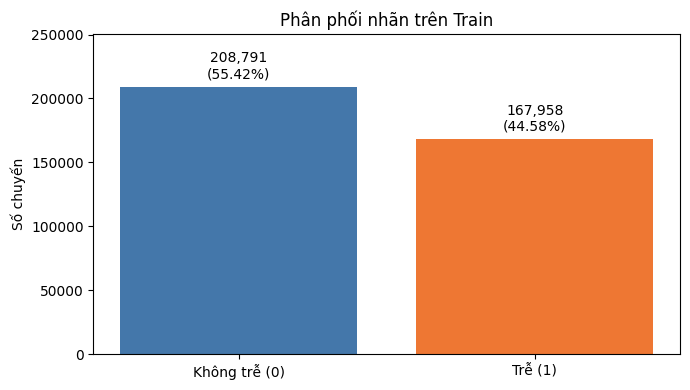

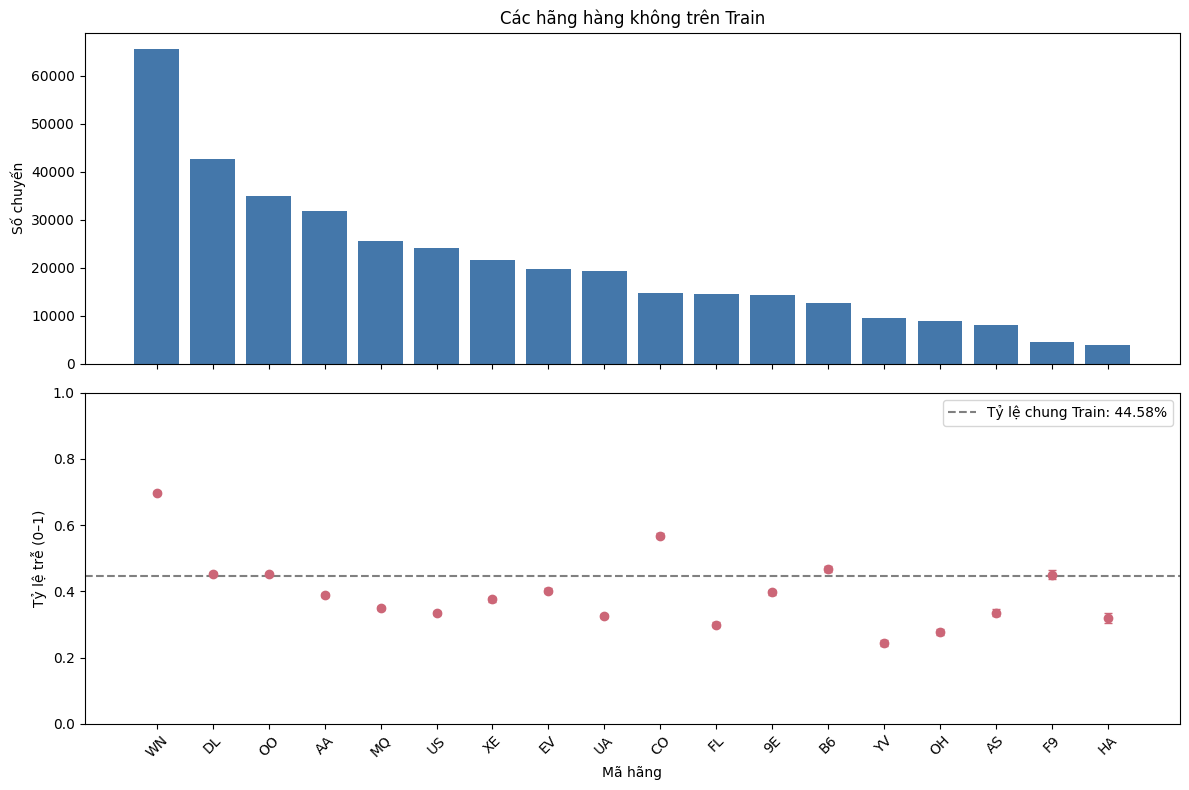

,Airline,n,delayed,rate,wilson_low,wilson_high
0,WN,65691,45900,0.6987,0.6952,0.7022
1,DL,42645,19289,0.4523,0.4476,0.4570
2,OO,34967,15778,0.4512,0.4460,0.4564
3,AA,31870,12413,0.3895,0.3841,0.3949
4,MQ,25577,8979,0.3511,0.3452,0.3569
5,US,24088,8090,0.3359,0.3299,0.3418
6,XE,21677,8145,0.3757,0.3693,0.3822
7,EV,19709,7923,0.4020,0.3952,0.4089
8,UA,19312,6302,0.3263,0.3197,0.3330
9,CO,14731,8369,0.5681,0.5601,0.5761


HOÀN TẤT: Đã lưu 2 hình và 2 bảng EDA trên Drive.


In [25]:
# Bước 24: EDA trên Train — phân phối nhãn và hãng hàng không

import matplotlib.pyplot as plt
import numpy as np

EDA_DIR = REPORT_DIR / "eda"
EDA_TABLE_DIR = REPORT_DIR / "eda_tables"
EDA_DIR.mkdir(parents=True, exist_ok=True)
EDA_TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Dùng bản Train đã đọc lại và kiểm tra ở Bước 22
train_eda = saved_parts["train"]

# --------------------------------------------------
# Hình 1: Số chuyến không trễ và trễ
# --------------------------------------------------
eda_labels = (
    train_eda.groupBy("Delay")
    .agg(F.count("*").alias("so_chuyen"))
    .orderBy("Delay")
    .toPandas()
)

eda_labels["ty_le"] = (
    eda_labels["so_chuyen"] / eda_labels["so_chuyen"].sum()
)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Không trễ (0)", "Trễ (1)"],
    eda_labels["so_chuyen"],
    color=["#4477AA", "#EE7733"]
)

ax.bar_label(
    bars,
    labels=[
        f"{n:,}\n({p:.2%})"
        for n, p in zip(eda_labels["so_chuyen"], eda_labels["ty_le"])
    ],
    padding=4
)

ax.set_title("Phân phối nhãn trên Train")
ax.set_ylabel("Số chuyến")
ax.set_ylim(0, eda_labels["so_chuyen"].max() * 1.2)

fig.tight_layout()
fig.savefig(EDA_DIR / "01_train_labels.png", dpi=160)
plt.show()
plt.close(fig)

# --------------------------------------------------
# Thống kê hãng và khoảng tin cậy Wilson 95%
# --------------------------------------------------
airline_stats = (
    train_eda.groupBy("Airline")
    .agg(
        F.count("*").alias("n"),
        F.sum("Delay").alias("delayed")
    )
    .orderBy(F.desc("n"), "Airline")
    .toPandas()
)

airline_stats["rate"] = airline_stats["delayed"] / airline_stats["n"]

n = airline_stats["n"].astype(float)
p = airline_stats["rate"]
z = 1.96

center = (p + z**2 / (2*n)) / (1 + z**2 / n)
half = (
    z * np.sqrt(p*(1-p)/n + z**2/(4*n**2))
    / (1 + z**2/n)
)

airline_stats["wilson_low"] = center - half
airline_stats["wilson_high"] = center + half

# --------------------------------------------------
# Hình 2: Số chuyến và tỷ lệ trễ theo hãng
# --------------------------------------------------
x = np.arange(len(airline_stats))
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].bar(x, airline_stats["n"], color="#4477AA")
axes[0].set_title("Các hãng hàng không trên Train")
axes[0].set_ylabel("Số chuyến")

axes[1].errorbar(
    x, airline_stats["rate"],
    yerr=[
        airline_stats["rate"] - airline_stats["wilson_low"],
        airline_stats["wilson_high"] - airline_stats["rate"]
    ],
    fmt="o", capsize=3, color="#CC6677"
)

train_delay_rate = (
    eda_labels.loc[eda_labels["Delay"] == 1, "ty_le"].iloc[0]
)

axes[1].axhline(
    train_delay_rate,
    linestyle="--", color="gray",
    label=f"Tỷ lệ chung Train: {train_delay_rate:.2%}"
)

axes[1].set_xticks(x, airline_stats["Airline"], rotation=45)
axes[1].set_ylabel("Tỷ lệ trễ (0–1)")
axes[1].set_xlabel("Mã hãng")
axes[1].set_ylim(0, 1)
axes[1].legend()

fig.tight_layout()
fig.savefig(EDA_DIR / "02_airlines.png", dpi=160)
plt.show()
plt.close(fig)

# Lưu số liệu đứng sau các hình
eda_labels.to_csv(
    EDA_TABLE_DIR / "labels_train.csv", index=False
)
airline_stats.to_csv(
    EDA_TABLE_DIR / "airlines_train.csv", index=False
)

display(airline_stats.round(4))
print("HOÀN TẤT: Đã lưu 2 hình và 2 bảng EDA trên Drive.")

Các biến chưa có: ['spark', 'train_eda', 'EDA_DIR', 'EDA_TABLE_DIR']
Thư mục dữ liệu trên Drive đang truy cập được: False


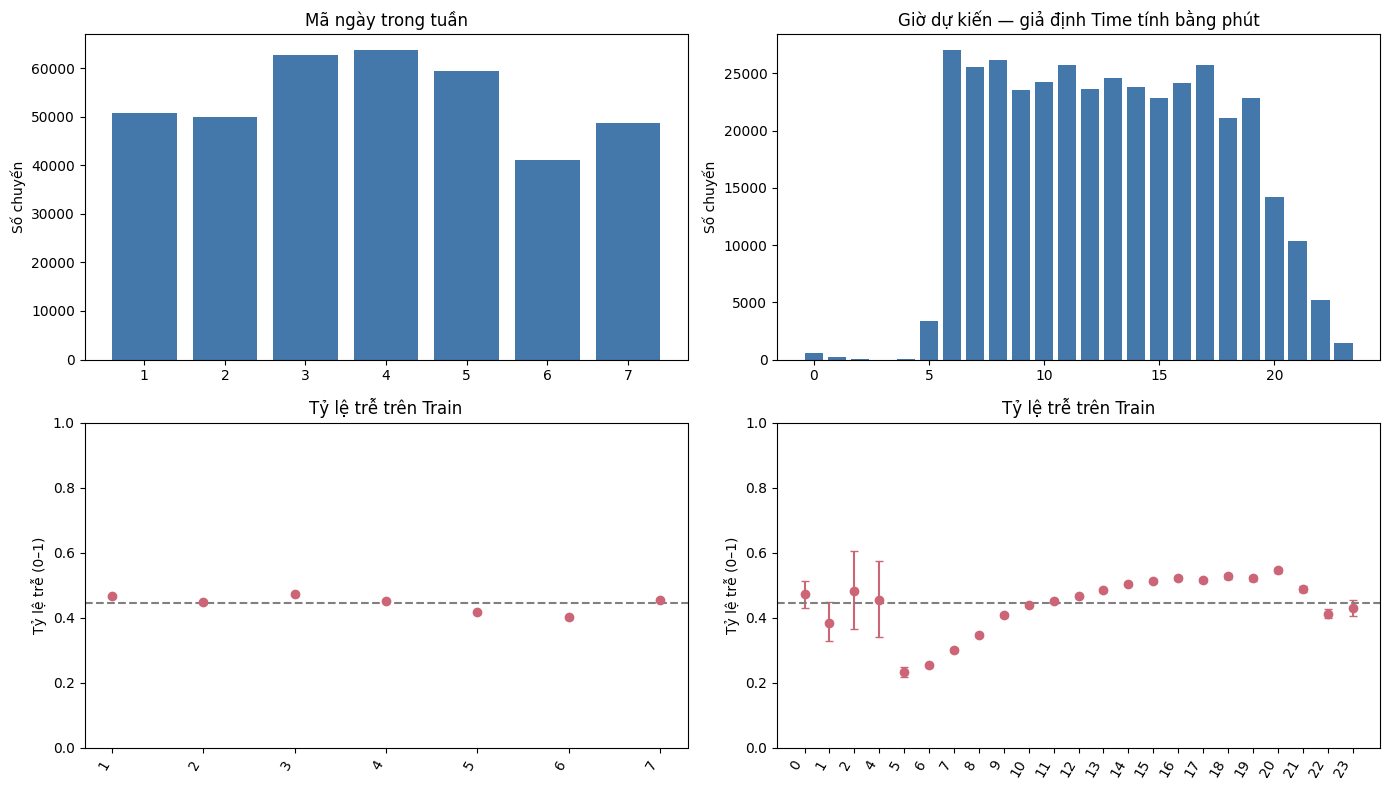

Đã lưu: 03_day_hour.png


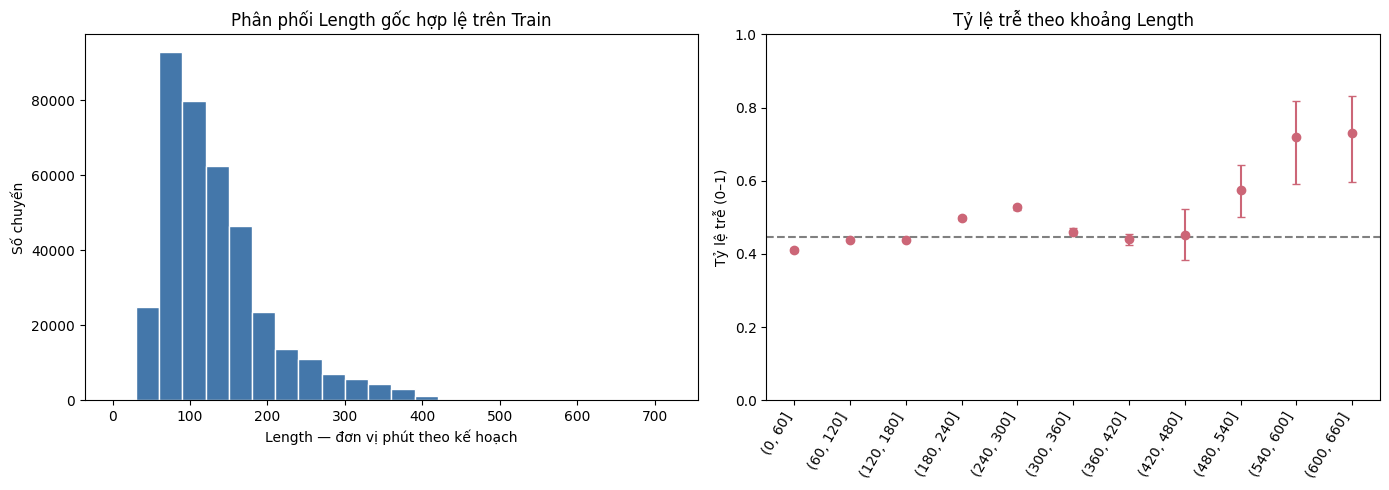

Đã lưu: 04_length.png


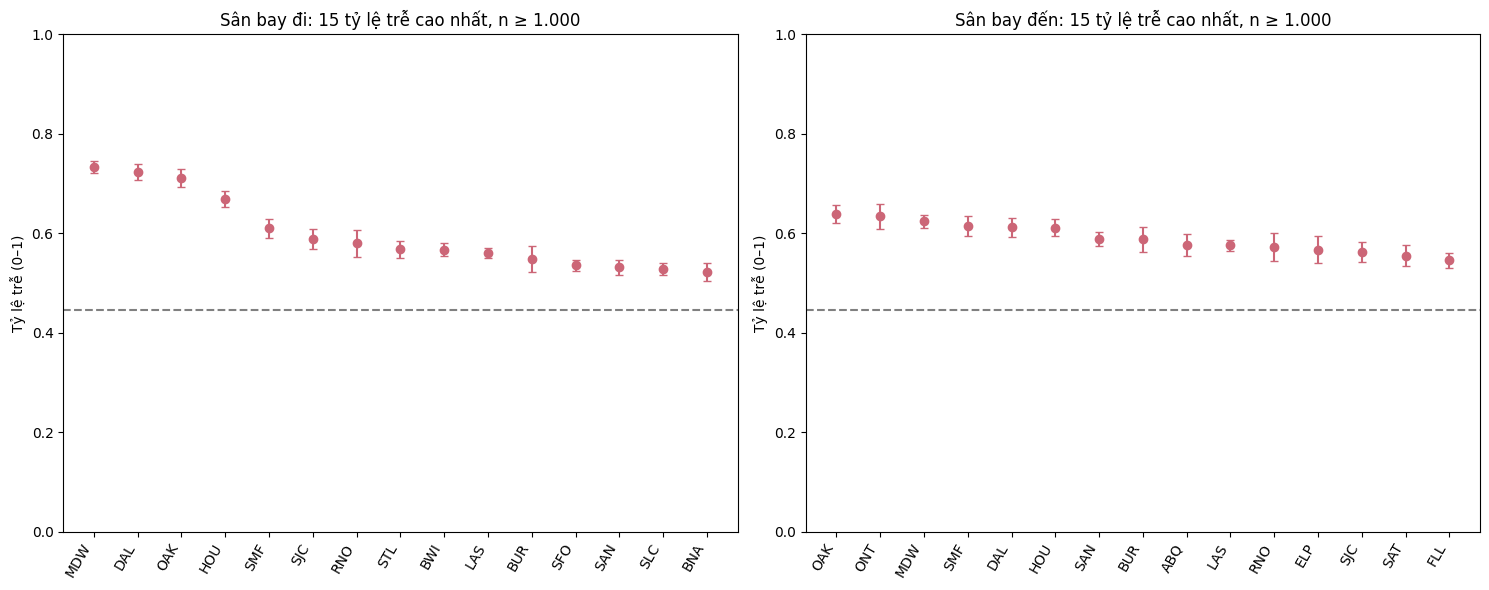

Đã lưu: 05_airports.png


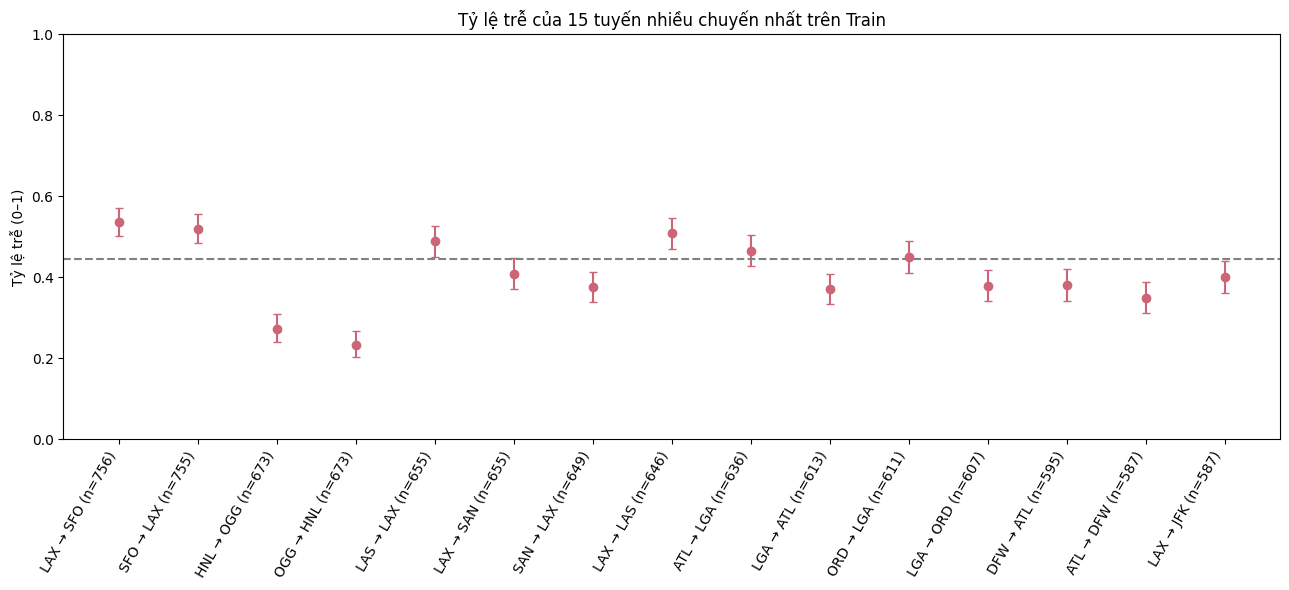

Đã lưu: 06_routes.png


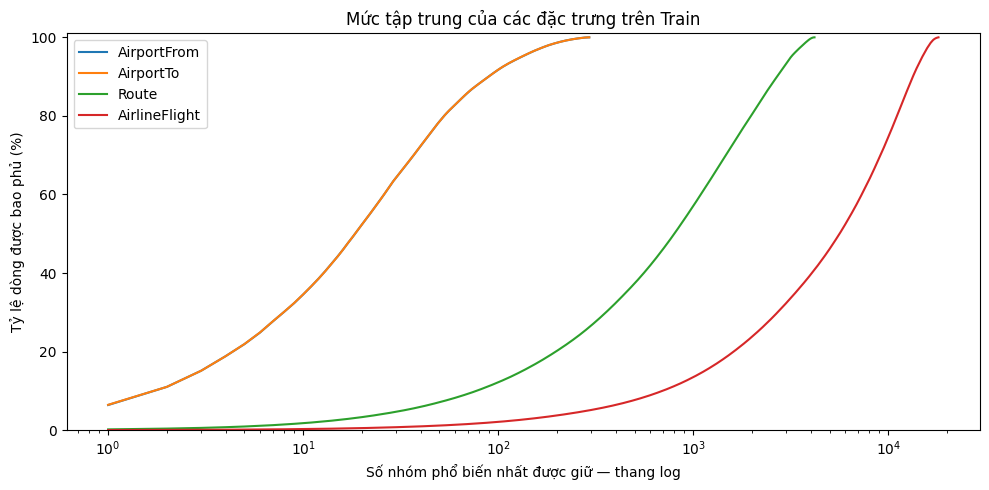

Đã lưu: 07_coverage.png


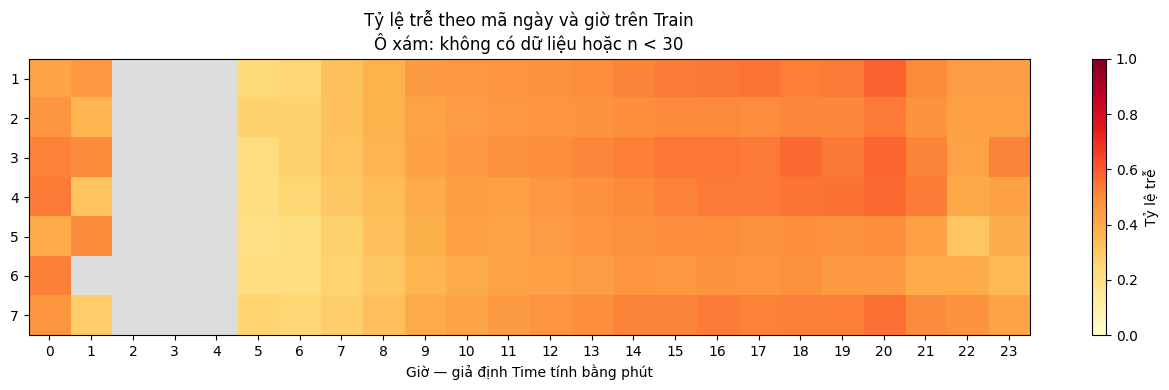

Đã lưu: 08_day_hour_heatmap.png


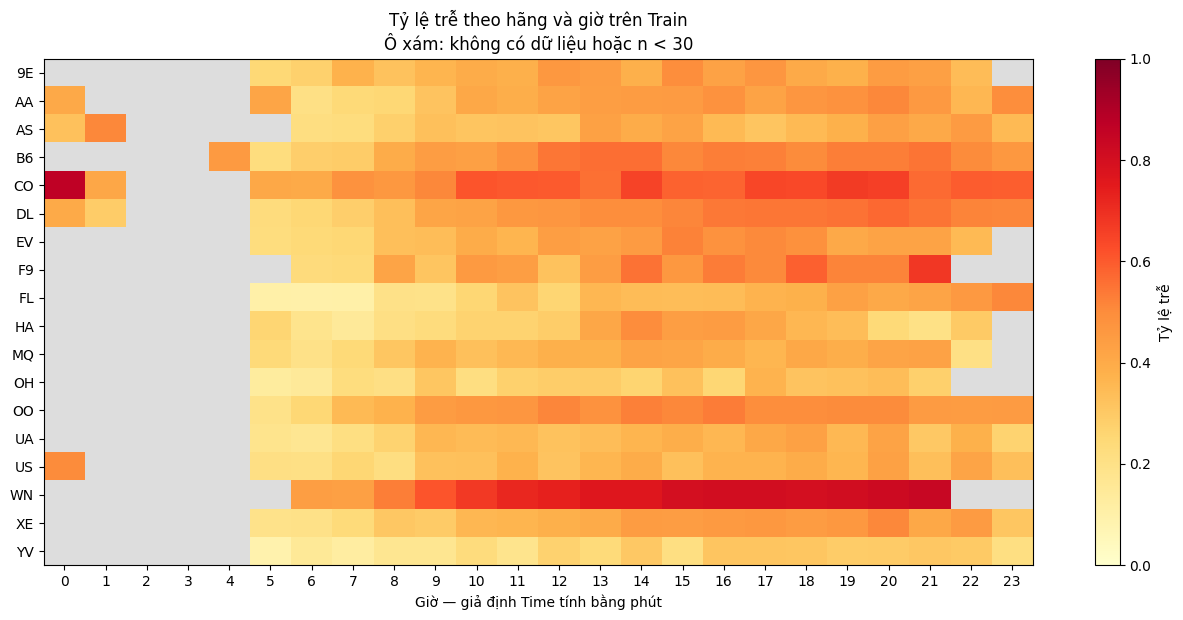

Đã lưu: 09_airline_hour_heatmap.png


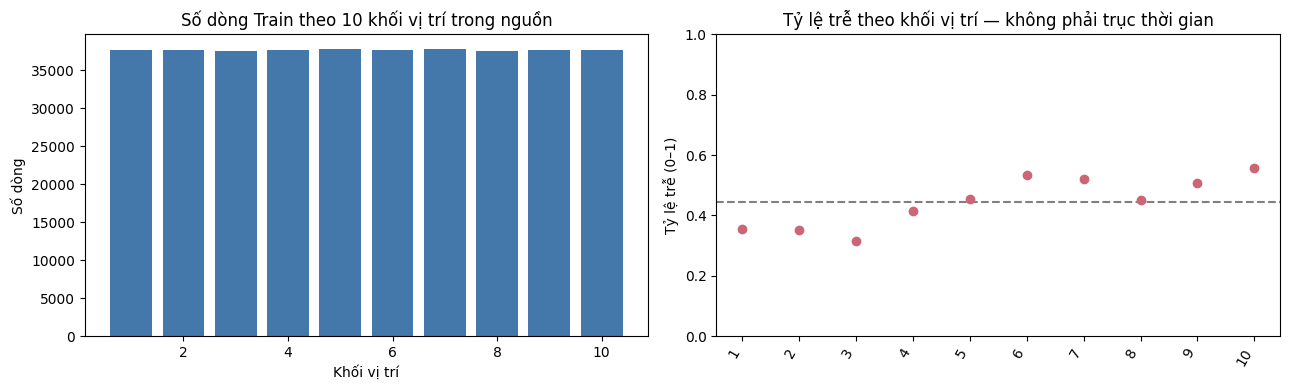

Đã lưu: 10_source_blocks.png


,nhom,muc,gia_tri,so_chuyen,ty_le_tre_phan_tram
0,Mã ngày,Cao nhất,3.0,62792,47.20
1,Mã ngày,Thấp nhất,6.0,41145,40.10
2,Giờ,Cao nhất,20.0,14230,54.63
3,Giờ,Thấp nhất,5.0,3358,23.32
4,Sân bay đi,Cao nhất,MDW,5007,73.30
5,Sân bay đi,Thấp nhất,OGG,1207,26.59
6,Sân bay đến,Cao nhất,OAK,2646,63.91
7,Sân bay đến,Thấp nhất,OGG,1253,28.89


HOÀN TẤT: Đã tạo và lưu thêm 8 hình EDA.
Cộng với 2 hình trước: đã có 10 hình.
Nơi lưu: /content/drive/MyDrive/BigData_Topic20/01_data_frozen/tv1_v1/reports/eda


In [9]:
# EDA CÒN LẠI — CHỈ DÙNG TRAIN
from pyspark.sql import functions as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

EDA_DIR.mkdir(parents=True, exist_ok=True)
EDA_TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Các cột phụ chỉ phục vụ báo cáo
eda = (
    train_eda
    .withColumn("Hour", F.floor(F.col("Time") / 60).cast("int"))
    .withColumn("DayCode", F.col("DayOfWeek").cast("int"))
    .withColumn("Route", F.concat_ws(" → ", "AirportFrom", "AirportTo"))
    .withColumn("AirlineFlight", F.concat_ws("_", "Airline", "Flight"))
    .withColumn(
        "SourceBlock",
        (F.floor(F.col("row_id") * 10 / 539383) + 1).cast("int")
    )
)

eda_tables = {}
eda_figures = []


# Hàm thống kê số chuyến, tỷ lệ trễ và khoảng Wilson 95%
def summarize(data, keys, name):
    table = (
        data.groupBy(*keys)
        .agg(
            F.count("*").alias("n"),
            F.sum("Delay").alias("delayed")
        )
        .orderBy(*keys)
        .toPandas()
    )

    n = table["n"].astype(float)
    p = table["delayed"] / n
    z = 1.96
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    half = half / denominator

    table["rate"] = p
    table["wilson_low"] = center - half
    table["wilson_high"] = center + half

    table.to_csv(
        EDA_TABLE_DIR / f"{name}.csv",
        index=False, encoding="utf-8-sig"
    )
    eda_tables[name] = table
    return table


def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(EDA_DIR / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    eda_figures.append(name)
    print("Đã lưu:", name)


def plot_rate(ax, table, key, title):
    x = np.arange(len(table))
    errors = np.maximum(0, np.vstack([
        table["rate"] - table["wilson_low"],
        table["wilson_high"] - table["rate"]
    ]))

    ax.errorbar(
        x, table["rate"], yerr=errors,
        fmt="o", capsize=3, color="#CC6677"
    )
    ax.axhline(train_delay_rate, color="gray", linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(table[key].astype(str), rotation=60, ha="right")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Tỷ lệ trễ (0–1)")
    ax.set_title(title)


# 3. Ngày trong tuần và giờ: cả số lượng lẫn tỷ lệ trễ
day_stats = summarize(eda, ["DayCode"], "day_train")
hour_stats = summarize(eda, ["Hour"], "hour_train")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for column, table, key, title in [
    (0, day_stats, "DayCode", "Mã ngày trong tuần"),
    (1, hour_stats, "Hour", "Giờ dự kiến — giả định Time tính bằng phút")
]:
    axes[0, column].bar(table[key], table["n"], color="#4477AA")
    axes[0, column].set_title(title)
    axes[0, column].set_ylabel("Số chuyến")
    plot_rate(axes[1, column], table, key, "Tỷ lệ trễ trên Train")

save_figure(fig, "03_day_hour.png")


# 4. Length: loại các giá trị đã điền khỏi thống kê quan sát gốc
length_observed = eda.filter(F.col("Length_invalid") == 0)
length_values = summarize(length_observed, ["Length"], "length_values_train")

length_bins = summarize(
    length_observed.withColumn(
        "LengthUpper", (F.ceil(F.col("Length") / 60) * 60).cast("int")
    ),
    ["LengthUpper"], "length_bins_train"
)
length_bins["bin_label"] = length_bins["LengthUpper"].map(
    lambda upper: f"({upper - 60}, {upper}]"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(
    length_values["Length"],
    bins=np.arange(0, 721, 30),
    weights=length_values["n"],
    color="#4477AA", edgecolor="white"
)
axes[0].set_title("Phân phối Length gốc hợp lệ trên Train")
axes[0].set_xlabel("Length — đơn vị phút theo kế hoạch")
axes[0].set_ylabel("Số chuyến")
plot_rate(
    axes[1], length_bins, "bin_label",
    "Tỷ lệ trễ theo khoảng Length"
)
save_figure(fig, "04_length.png")


# 5–6. Sân bay và tuyến bay: chỉ xếp hạng nhóm có ít nhất 1.000 dòng
MIN_GROUP_N = 1000

from_stats = summarize(eda, ["AirportFrom"], "airport_from_train")
to_stats = summarize(eda, ["AirportTo"], "airport_to_train")
route_stats = summarize(eda, ["Route"], "routes_train")


def eligible_top(table, key):
    return (
        table.loc[table["n"] >= MIN_GROUP_N]
        .sort_values(["rate", key], ascending=[False, True])
        .head(15)
        .reset_index(drop=True)
    )


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, table, key, title in [
    (axes[0], from_stats, "AirportFrom", "Sân bay đi"),
    (axes[1], to_stats, "AirportTo", "Sân bay đến")
]:
    plot_rate(
        ax, eligible_top(table, key), key,
        f"{title}: 15 tỷ lệ trễ cao nhất, n ≥ 1.000"
    )
save_figure(fig, "05_airports.png")

# Chọn 15 tuyến nhiều chuyến nhất để mô tả trên Train
top_routes = (
    route_stats.sort_values(["n", "Route"], ascending=[False, True])
    .head(15)
    .copy()
)
top_routes["nhan"] = (
    top_routes["Route"] + " (n=" + top_routes["n"].astype(str) + ")"
)

fig, ax = plt.subplots(figsize=(13, 6))
plot_rate(
    ax, top_routes, "nhan",
    "Tỷ lệ trễ của 15 tuyến nhiều chuyến nhất trên Train"
)
save_figure(fig, "06_routes.png")


# 7. Mức tập trung: top-k nhóm chiếm bao nhiêu phần trăm dữ liệu?
flight_stats = summarize(eda, ["AirlineFlight"], "airline_flight_train")
coverage_rows = []

fig, ax = plt.subplots(figsize=(10, 5))
for name, table in [
    ("AirportFrom", from_stats),
    ("AirportTo", to_stats),
    ("Route", route_stats),
    ("AirlineFlight", flight_stats)
]:
    counts = table["n"].sort_values(ascending=False).to_numpy()
    coverage = np.cumsum(counts) / counts.sum()
    ax.plot(np.arange(1, len(counts) + 1), coverage * 100, label=name)

    for k in [10, 20, 50, 100]:
        actual_k = min(k, len(counts))
        coverage_rows.append({
            "feature": name,
            "requested_top_k": k,
            "actual_top_k": actual_k,
            "coverage_percent": coverage[actual_k - 1] * 100
        })

coverage_report = pd.DataFrame(coverage_rows)
coverage_report.to_csv(
    EDA_TABLE_DIR / "coverage_train.csv", index=False
)
ax.set_xscale("log")
ax.set_xlabel("Số nhóm phổ biến nhất được giữ — thang log")
ax.set_ylabel("Tỷ lệ dòng được bao phủ (%)")
ax.set_title("Mức tập trung của các đặc trưng trên Train")
ax.set_ylim(0, 101)
ax.legend()
save_figure(fig, "07_coverage.png")


# 8–9. Heatmap: ẩn ô có ít hơn 30 dòng để tránh diễn giải mẫu quá nhỏ
def make_heatmap(row_key, row_order, filename, title):
    table = summarize(eda, [row_key, "Hour"], filename.removesuffix(".png"))
    rates = table.pivot(index=row_key, columns="Hour", values="rate")
    counts = table.pivot(index=row_key, columns="Hour", values="n")

    rates = rates.reindex(index=row_order, columns=range(24))
    counts = counts.reindex(index=row_order, columns=range(24))
    rates = rates.where(counts >= 30)

    fig, ax = plt.subplots(figsize=(13, max(4, len(row_order) * 0.35)))
    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("#dddddd")
    heat = ax.imshow(
        np.ma.masked_invalid(rates.to_numpy(dtype=float)),
        aspect="auto", vmin=0, vmax=1, cmap=cmap
    )
    ax.set_xticks(range(24))
    ax.set_yticks(range(len(row_order)))
    ax.set_yticklabels(row_order)
    ax.set_xlabel("Giờ — giả định Time tính bằng phút")
    ax.set_title(title + "\nÔ xám: không có dữ liệu hoặc n < 30")
    fig.colorbar(heat, ax=ax, label="Tỷ lệ trễ")
    save_figure(fig, filename)


make_heatmap(
    "DayCode", list(range(1, 8)), "08_day_hour_heatmap.png",
    "Tỷ lệ trễ theo mã ngày và giờ trên Train"
)
make_heatmap(
    "Airline", sorted(airline_stats["Airline"].tolist()),
    "09_airline_hour_heatmap.png",
    "Tỷ lệ trễ theo hãng và giờ trên Train"
)


# 10. Khối vị trí trong nguồn — không xem đây là ngày/tháng thực tế
block_stats = summarize(eda, ["SourceBlock"], "source_blocks_train")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(block_stats["SourceBlock"], block_stats["n"], color="#4477AA")
axes[0].set_title("Số dòng Train theo 10 khối vị trí trong nguồn")
axes[0].set_xlabel("Khối vị trí")
axes[0].set_ylabel("Số dòng")
plot_rate(
    axes[1], block_stats, "SourceBlock",
    "Tỷ lệ trễ theo khối vị trí — không phải trục thời gian"
)
save_figure(fig, "10_source_blocks.png")


# Tóm tắt để xem kết quả và viết nhận xét ở bước tiếp theo
summary_rows = []
for name, table, key, minimum in [
    ("Mã ngày", day_stats, "DayCode", 1),
    ("Giờ", hour_stats, "Hour", 30),
    ("Sân bay đi", from_stats, "AirportFrom", MIN_GROUP_N),
    ("Sân bay đến", to_stats, "AirportTo", MIN_GROUP_N),
    ("Tuyến", route_stats, "Route", MIN_GROUP_N)
]:
    valid = table.loc[table["n"] >= minimum]
    if valid.empty:
        continue
    for description, row in [
        ("Cao nhất", valid.loc[valid["rate"].idxmax()]),
        ("Thấp nhất", valid.loc[valid["rate"].idxmin()])
    ]:
        summary_rows.append({
            "nhom": name,
            "muc": description,
            "gia_tri": row[key],
            "so_chuyen": int(row["n"]),
            "ty_le_tre_phan_tram": round(float(row["rate"]) * 100, 2)
        })

eda_summary = pd.DataFrame(summary_rows)
eda_summary.to_csv(
    EDA_TABLE_DIR / "eda_summary.csv",
    index=False, encoding="utf-8-sig"
)
display(eda_summary)

assert len(eda_figures) == 8
assert all((EDA_DIR / name).is_file() for name in eda_figures)
print("HOÀN TẤT: Đã tạo và lưu thêm 8 hình EDA.")
print("Cộng với 2 hình trước: đã có 10 hình.")
print("Nơi lưu:", EDA_DIR)